In [19]:
import math
pi = math.pi
import matplotlib.pyplot as plt
import numpy as np
# Suppress warnings
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
import matplotlib
# Integration
import scipy.integrate as integrate

In [2]:
matplotlib.rcParams.update({'text.usetex': True})
plt.rcParams.update({
       "text.usetex": True,
       "font.family": "serif",
       "font.size": 16,
       "axes.labelsize": 16,
       "axes.titlesize": 16,
       "legend.fontsize": 14,
       "xtick.labelsize": 14,
       "ytick.labelsize": 14,
})

### Quantum Dots' Parametrs

$ɛ = 1$ On-site mean local energy

$ɛ_L = ɛ + \frac{1}{2}δ$ On-site mean left energy

$ɛ_R = ɛ - \frac{1}{2}δ$ On-site mean right energy

$δ = 0.0$ detuning

$g = 0.5$ coupling strength

$Δ=\sqrt{δ^2+g^2}$

$\Gamma = 0.02$ coupling to the reservoirs (the overall frequency scale of the dissipative dynamics)

$Ω=100$ Intra-reservoir tunnelling energy/hopping amplitude


In [3]:
# Quantum Dots' Parametrs
eps = 1.0 # on-site mean local energy
delta = np.linspace(0.0,1.5,11)
eps_L = eps + 0.5 * delta
eps_R = eps - 0.5 * delta
g = 0.5 # coupling strength
Delta  = np.sqrt(delta**2 + g**2)
Gamma = 2e-2 
Omega = 100.0 # intra-reservoir tunnelling energy/hopping amplitude

### Basis Energies

$E_1 = ɛ+ \frac{Δ}{2}$

$E_1 = ɛ- \frac{Δ}{2}$

In [4]:
# Basis Energies
E1 = eps + 0.5*Delta
E2 = eps - 0.5*Delta

### Reservoirs' parameters


$T/\varepsilon = 0.02 - 2$ Temperature of the reservoirs 

$\mu_L/\varepsilon = 0.7$ Electrochemical potential of the left reservoir

$\mu_R/\varepsilon = 0.0$ Electrochemical potential of the right reservoir

In [5]:
# Reservoirs' parameters
T = np.linspace(2e-2, 2e-0, 501)
muL = 0.7
muR = 0.0

### Fermi-Dirac fucntion

\begin{equation*}
f(\omega) = \frac{1}{e^{β(\omega-\mu)}+1}
\end{equation*}


In [6]:
# Dimensionless Fermi-Dirac fucntion expressed with reduced variable x=beta*(E-mu)
f = lambda x: 1./(1. + np.exp(x))

### Spectral density

\begin{align*}
\mathcal{J}_N(\omega) = \frac{\Gamma}{2\pi} \sqrt{1 - \frac{\omega^2}{\Omega^2}} \, \Theta(\Omega - |\omega|)
\end{align*}
### Propability Destribution of Excitation Energy

\begin{align*}
\varphi_j(\omega)=\frac{1}{1-\Gamma / \Omega} \frac{\mathcal{J}_{\mathrm{N}}(\omega)}{\left(\omega-E_j^{\prime}\right)^2+\Gamma_j^2 / 4}
\end{align*}
### Shifted Energies and Decay Rates

\begin{align*}
E'_j = \frac{1 - \Gamma / 2\Omega}{1 - \Gamma / \Omega} E_j, \quad
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma.
\end{align*}
### Transmission function

\begin{align*}
\mathcal{T}(\omega)=\frac{\pi g^2}{2} \varphi_1(\omega) \varphi_2(\omega)
\end{align*}

### Uder Exponential-propagator approximation (EPA)

\begin{align*}
E'_j \approx E_j, \quad
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma  \approx 2 \pi \mathcal{J}_N(E_j).
\end{align*}

In [7]:
# Spectral density
def J(omega, Gamma, Omega):
     return Gamma/(2.0*np.pi)*np.sqrt(1.0-omega**2/Omega**2)*np.heaviside(Omega-abs(omega),0)
#  Probability distribution of excitation energy
def phi(omega, Gamma, Omega, E):
    E_dash = E
    Gamma_dash = 2.0*np.pi*J(E_dash, Gamma, Omega)
    return 1.0/((omega-E_dash)**2+(Gamma_dash/2.0)**2)*J(omega, Gamma, Omega)
# Gamma j
Gamma_function = lambda Gamma, Omega, E: (2.0*np.pi*J(E, Gamma, Omega))

### Non-additivity in the local basis

### Orthogonal Rotation Matrix

\begin{equation*}
R = \frac{1}{\sqrt{2\Delta}}
\left(
\begin{array}{cc}
\sqrt{\Delta + \delta} & -\sqrt{\Delta - \delta} \\ \sqrt{\Delta - \delta} & \sqrt{\Delta + \delta}
\end{array}
\right)
\end{equation*}

In [8]:
# Orthogonal rotation matrix
R = 1.0/np.sqrt(2 * Delta) * np.array([[np.sqrt(Delta+delta), -np.sqrt(Delta-delta)],[np.sqrt(Delta-delta), np.sqrt(Delta+delta)]])

### Decay Rates

\begin{align*}
\Gamma_j = \frac{\sqrt{1 - \Gamma / \Omega - E_j^2 / \Omega^2}}{1 - \Gamma / \Omega} \Gamma \approx 2 \pi \mathcal{J}_N(E_j)
\end{align*}

### Gammas
$ \Gamma_{L,j}= \Gamma_{j}R_{1j}^2$

$ \Gamma_{R,j}= \Gamma_{j}R_{2j}^2$

$j=1,2$

In [9]:
# Gamma_L,1
GammaL1 = Gamma_function(Gamma, Omega, E1) * R[0,0]**2
# Gamma_L,2
GammaL2 = Gamma_function(Gamma, Omega, E2) * R[0,1]**2
# Gamma_R,1
GammaR1 = Gamma_function(Gamma, Omega, E1) * R[1,0]**2
# Gamma_R,1
GammaR2 = Gamma_function(Gamma, Omega, E2) * R[1,1]**2

In [10]:
# Decay and gain rates
def dg_m(omega, Gamma, Omega, E, mu, T):
  return phi(omega, Gamma, Omega, E) * (1.0 - f((omega-mu)/T))
def dg_p(omega, Gamma, Omega, E, mu, T):
  return phi(omega, Gamma, Omega, E) * f((omega-mu)/T)

### Deacay and Gian Rates

\begin{align*}
\gamma_{\alpha, j}^{-}=\Gamma_{\alpha, j} \int \mathrm{~d} \omega \ \varphi_j(\omega)[1-f_{α}(ω)] \\
\gamma_{\alpha, j}^{+}=\Gamma_{\alpha, j} \int \mathrm{~d} \omega \ \varphi_j(\omega)f_{α}(ω) \\
\end{align*}




In [11]:
# Decay and gain rates
gammaL1_m, gammaR1_m, gammaL2_m, gammaR2_m = np.zeros((np.size(delta),np.size(T))), np.zeros((np.size(delta),np.size(T))), np.zeros((np.size(delta),np.size(T))), np.zeros((np.size(delta),np.size(T)))
gammaL1_p, gammaR1_p, gammaL2_p, gammaR2_p = np.zeros((np.size(delta),np.size(T))), np.zeros((np.size(delta),np.size(T))), np.zeros((np.size(delta),np.size(T))), np.zeros((np.size(delta),np.size(T)))
for i in range(np.size(delta)): #
  for j in range(np.size(T)):
    gammaL1_m[i,j] = GammaL1[i]*integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E1[i], muL, T[j]), points = [E1[i]], epsabs=1.49e-7,epsrel=1.49e-14)[0]
    gammaR1_m[i,j] = GammaR1[i]*integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E1[i], muR, T[j]), points = [E1[i]], epsabs=1.49e-7,epsrel=1.49e-14)[0]
    gammaL2_m[i,j] = GammaL2[i]*integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E2[i], muL, T[j]), points = [E2[i]], epsabs=1.49e-7,epsrel=1.49e-14)[0]
    gammaR2_m[i,j] = GammaR2[i]*integrate.quad(dg_m,-Omega,Omega,args=(Gamma, Omega, E2[i], muR, T[j]), points = [E2[i]], epsabs=1.49e-7,epsrel=1.49e-14)[0]

    gammaL1_p[i,j] = GammaL1[i]*integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E1[i], muL, T[j]), points = [E1[i]], epsabs=1.49e-7,epsrel=1.49e-14)[0]
    gammaR1_p[i,j] = GammaR1[i]*integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E1[i], muR, T[j]), points = [E1[i]], epsabs=1.49e-7,epsrel=1.49e-14)[0]
    gammaL2_p[i,j] = GammaL2[i]*integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E2[i], muL, T[j]), points = [E2[i]], epsabs=1.49e-7,epsrel=1.49e-14)[0]
    gammaR2_p[i,j] = GammaR2[i]*integrate.quad(dg_p,-Omega,Omega,args=(Gamma, Omega, E2[i], muR, T[j]), points = [E2[i]], epsabs=1.49e-7,epsrel=1.49e-14)[0]

### Non-additive Rates
$\overline{γ}^{\pm}_{\alpha} = {γ}^{\pm}_{1,\alpha} + {γ}^{\pm}_{2,\alpha}$


In [12]:
# Dash rates
gammaL_m_dash = (gammaL1_m + gammaL2_m)
gammaR_m_dash = (gammaR1_m + gammaR2_m)
gammaL_p_dash = (gammaL1_p + gammaL2_p)
gammaR_p_dash = (gammaR1_p + gammaR2_p)

### Delocalised Lindblad Dissipators

\begin{equation*}
\bar{\mathcal{L}}_{LR} \hat{\rho}_S = \sum_{\alpha \neq \alpha'} \left[ \bar{\Lambda}_{\alpha \alpha'}^+ \left( \hat{c}_{\alpha'}^\dagger  \hat{\rho}_S \hat{c}_\alpha - \frac{1}{2} \{ \hat{c}_\alpha \hat{c}_{\alpha'}^\dagger, \hat{\rho }_S \} \right) + \bar{\Lambda}_{\alpha \alpha'}^- \left( \hat{c}_{\alpha} \hat{\rho }_S \hat{c}_{\alpha'}^\dagger - \frac{1}{2} \{ \hat{c}_{\alpha'}^\dagger \hat{c}_\alpha, \hat{\rho }_S \} \right) \right]
\end{equation*}

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}=({\bar{\Lambda}}_{RL}^{\pm})^*
\end{equation*}

In [13]:
# Lamda LR PM matrix: Re and Im parts
def dLambda_dash_p_re(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)-Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(f((omega-muL)/T)+f((omega-muR)/T))
def dLambda_dash_p_im(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return ((E1-omega)*phi(omega, Gamma, Omega, E1)-(E2-omega)*phi(omega, Gamma, Omega, E2))*(f((omega-muL)/T)-f((omega-muR)/T))
def dLambda_dash_m_re(omega, Gamma, Omega, E1, E2, muL, muR, T):
  return (Gamma_function(Gamma, Omega, E2)*phi(omega, Gamma, Omega, E2)-Gamma_function(Gamma, Omega, E1)*phi(omega, Gamma, Omega, E1))*(2.0 - f((omega-muL)/T)-f((omega-muR)/T))

### Re and Im Parts

\begin{align*}
\text{Re} [\bar{\Lambda}^{+}_{LR}] &= \frac{g}{4\Delta} \int d\omega \left[ \Gamma_2 \varphi_2(\omega) - \Gamma_1 \varphi_1(\omega) \right] \left[ f_L(\omega) + f_R(\omega) \right], \\
\text{Im} [\bar{\Lambda}^{+}_{LR}] &= \frac{g}{2\Delta} \int d\omega \left[ (E_1 - \omega) \varphi_1(\omega) - (E_2 - \omega) \varphi_2(\omega) \right] \left[ f_L(\omega) - f_R(\omega) \right], \\
\text{Re} [\bar{\Lambda}^{-}_{LR}] &= \frac{g}{4\Delta} \int d\omega \left[ \Gamma_2 \varphi_2(\omega) - \Gamma_1 \varphi_1(\omega) \right] \left[ 2 - f_L(\omega) - f_R(\omega) \right], \\
\text{Im} [\bar{\Lambda}^{-}_{LR}] &= -\text{Im} [\bar{\Lambda}^{+}_{LR}].
\end{align*}

In [14]:
# Lamda LR PM matrix: Re and Im parts
Lambda_dash_p_re, Lambda_dash_p_im, Lambda_dash_m_re, Lambda_dash_m_im = np.zeros((np.size(Delta),np.size(T))), np.zeros((np.size(Delta),np.size(T))), np.zeros((np.size(Delta),np.size(T))),np.zeros((np.size(Delta),np.size(T)))
for i in range(np.size(Delta)):
  for j in range(np.size(T)):
    Lambda_dash_p_re[i,j] = g/(4*Delta[i])*integrate.quad(dLambda_dash_p_re,-Omega,Omega,args=(Gamma, Omega, E1[i], E2[i], muL, muR, T[j] ), epsabs=1.49e-10,epsrel=1.49e-14)[0]
    Lambda_dash_p_im[i,j] = g/(2*Delta[i])*integrate.quad(dLambda_dash_p_im,-Omega,Omega,args=(Gamma, Omega, E1[i], E2[i], muL, muR, T[j]), epsabs=1.49e-10,epsrel=1.49e-14)[0]
    Lambda_dash_m_re[i,j] = g/(4*Delta[i])*integrate.quad(dLambda_dash_m_re,-Omega,Omega,args=(Gamma, Omega, E1[i], E2[i], muL, muR, T[j]), epsabs=1.49e-10,epsrel=1.49e-14)[0]
    Lambda_dash_m_im[i,j] = -Lambda_dash_p_im[i,j]

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}= \mathrm{Re}~ {\bar{\Lambda}}_{LR}^{\pm} + \mathrm{i}~ \mathrm{Im}~ {\bar{\Lambda}}_{LR}^{\pm}
\end{equation*}

In [15]:
# Lamda LR PM matrix:
Lambda_dash_p_LR = Lambda_dash_p_re + 1j * Lambda_dash_p_im
Lambda_dash_m_LR = Lambda_dash_m_re + 1j * Lambda_dash_m_im

\begin{equation*}
{\bar{\Lambda}}_{LR}^{\pm}=({\bar{\Lambda}}_{RL}^{\pm})^*
\end{equation*}

In [16]:
# Lamda RL PM matrix:
Lambda_dash_p_RL = Lambda_dash_p_LR.conjugate()
Lambda_dash_m_RL = Lambda_dash_m_LR.conjugate()

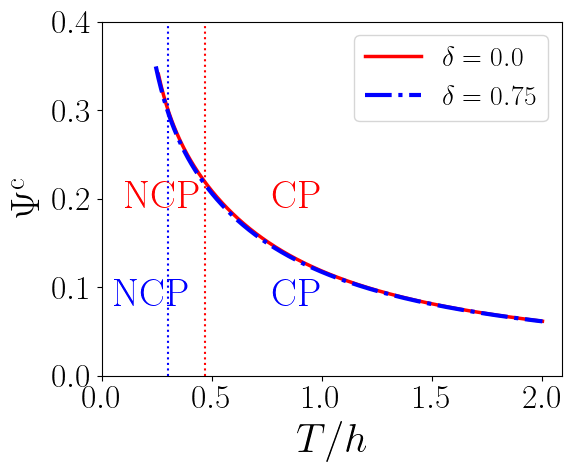

In [35]:
fig = plt.figure(figsize=(6.0, 5))

plt.tick_params(axis='both', which='major', labelsize=24)
plt.plot(T[60:], (abs(Lambda_dash_p_LR[0,60:])*abs(Lambda_dash_p_RL[0,60:]))**0.5/(gammaL_p_dash[0,60:]*gammaL_m_dash[0,60:]*gammaR_p_dash[0,60:]*gammaR_m_dash[0,60:])**0.25, label=r'$ \delta=0.0$', color = 'red', linewidth=2.5 )
plt.plot(T[57:], (abs(Lambda_dash_p_LR[5,57:])*abs(Lambda_dash_p_RL[5,57:]))**0.5/(gammaL_p_dash[5,57:]*gammaL_m_dash[5,57:]*gammaR_p_dash[5,57:]*gammaR_m_dash[5,57:])**0.25, label=r'$ \delta=0.75$', color = 'blue', linewidth=3.0, linestyle='-.' )

plt.axvline(x=T[113], color='red', linestyle=':')
plt.axvline(x=T[71], color='blue', linestyle=':')
# plt.text(0.3, 1.3, r"$(a)$",{'color': 'black', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');

plt.text(1.0, 0.2, r"CP",{'color': 'red', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
plt.text(0.45, 0.2, r"NCP",{'color': 'red', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');


plt.text(1.0, 0.09, r"CP",{'color': 'blue', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');
plt.text(0.4, 0.09, r"NCP",{'color': 'blue', 'fontsize': 28}, horizontalalignment='right', verticalalignment='center');


plt.xlabel(r'$T/h$', fontsize=30); plt.ylabel(r'$\Psi^{\rm{c}}$', fontsize=30)
plt.xticks(np.arange(0, 2.1, 0.5))
plt.yticks(np.arange(0, 0.41, 0.1))
plt.legend(fontsize=20)

plt.tight_layout()
plt.show()
fig.savefig('/Users/iliakhomchenko/Desktop/Postdoc/Non-Markovianity/Code/GitHub_V2/approximation_local_v2.pdf', format='pdf');